In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

from dotenv import dotenv_values

In [3]:
# Load config file agnostic to project or notebook work directory
config_path = Path("config.env")
if not config_path.exists():
    config_path = Path("../../../config.env")
CONFIG = dotenv_values(config_path)
assert CONFIG != {}, 'Configuration is empty - check the filepath.'

# Plotting defaults
MM = 1/25.4
RCPARAMS = '../../../resources/figures.mplstyle'

# Main data directory
DATADIR = Path(CONFIG['DATADIR'])

# Submodule specific data directory
OUTDIR = DATADIR / '10_analyses' / 'sexual_dimorphism'
OUTDIR.mkdir(parents=True, exist_ok=True)
FIGUREDIR = DATADIR / 'publication' / 'Fig_04'

# notebook-specific constants
SIG_THRESHOLD = 0.05
N_SIG_CLUSTER_THRESHOLD = 10

In [4]:
fp_global_go_results = OUTDIR / 'GO_results' / 'global' / 'results.csv'
df_global_go_results = pd.read_csv(fp_global_go_results, index_col=0)
df_global_go_results.shape, df_global_go_results.columns

((26, 17),
 Index(['description', 'effective_domain_size', 'goshv', 'highlighted',
        'intersection_size', 'name', 'native', 'p_value', 'precision', 'query',
        'query_size', 'recall', 'significant', 'source', 'term_size',
        'source_order', 'group_id'],
       dtype='object'))

In [5]:
df_global_go_results['-log10(pvalue)'] = -np.log10(df_global_go_results['p_value'])
df_global_go_results = df_global_go_results.sort_values(['highlighted', '-log10(pvalue)'], ascending=False)

52.5


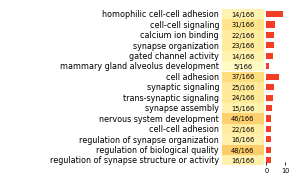

In [6]:
from matplotlib import pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle

def plot_pathway_results(data):
    n_rows = data.shape[0]

    # plt.rcParams['font.family'] = 'monospace'

    print(3.5*n_rows)
    fig, axes = plt.subplots(n_rows, 3, figsize=(75*MM, 3*MM*n_rows),
                            gridspec_kw={'width_ratios': [10, 2, 1], 'wspace': 0.03, 'hspace': 0.02},
                            sharey=True)
    axes = np.atleast_2d(axes)

    cmap = plt.get_cmap('YlOrRd')
    norm_pct = Normalize(vmin=0, vmax=1)
    norm_pval = Normalize(vmin=-32, vmax=16)

    for i, (_, row) in enumerate(data.iterrows()):
        ax1, ax2, ax3 = axes[i]
        
        # Name column
        s = row['name']
        if len(s) > 50:
            s = s[:44] + "..."

        # Term Name ------------------------------------------------------------------ #
        ax1.text(1, 0.5, s, va='center', ha='right', fontsize=6, weight='light')
        ax1.grid(False)
        ax1.set_ylim(0, 1)
        ax1.axis('off')
        ax1.set_xticks([])        # remove x ticks
        ax1.set_yticks([])        # remove y ticks
        ax1.spines['top'].set_visible(False)
        ax1.spines['right'].set_visible(False)
        ax1.spines['left'].set_visible(False)
        ax1.spines['bottom'].set_visible(False)
        # ax1.set_facecolor('#f0f0f0')  # keep the light grey background
        

        # Precision Indicator -------------------------------------------------------- #
        ax2.grid(False)
        ax2.set_xticks([])        # remove x ticks
        ax2.set_yticks([])        # remove y ticks
        ax2.spines['top'].set_visible(False)
        ax2.spines['right'].set_visible(False)
        ax2.spines['left'].set_visible(False)
        ax2.spines['bottom'].set_visible(False)
        
        color = cmap(norm_pct(row['precision']))
        # ax2.set_facecolor(color)  # keep the light grey background
        ax2.add_patch(Rectangle(
            (0, 0), 1, 1,
            color=color, lw=0, zorder=0
        ))
        ax2.text(0.5, 0.5, f"{row['intersection_size']}/{row['query_size']}", va='center', ha='center', fontsize=5)
        ax2.set_ylim(0,1)
        ax2.set_xlim(0,1)

        # Significance Indicator ----------------------------------------------------- #
        color = cmap(norm_pval(row['p_value']))
        ax3.barh(0.5, -np.log10(row['p_value']), color=color, height=0.6)
        ax3.grid(False)
        ax3.set_xlim(0, 11)
        if i == data.shape[0]-1:
            # ax3.xaxis.set_ticks_position('top')
            # ax3.xaxis.set_label_position('top')
            ax3.xaxis.set_tick_params(labelsize=5)
        else:
            ax3.set_xticks([])       # remove x ticks
        ax3.set_yticks([])        # remove y ticks
        ax3.spines['top'].set_visible(False)
        ax3.spines['right'].set_visible(False)
        ax3.spines['left'].set_visible(False)
        ax3.spines['bottom'].set_visible(False)
        # ax3.set_facecolor('#f0f0f0')  # keep the light grey background

    # plt.tight_layout()
    return fig

with plt.style.context(RCPARAMS):
    plt.close('all')
    fig = plot_pathway_results(df_global_go_results.head(15))
    fig.subplots_adjust(bottom=0.08, top=1, right=0.98, left=0, hspace=0, wspace=0.05)
    fig.savefig(FIGUREDIR / 'subplot_b_global_pathways.pdf', transparent=True)
    plt.show()